# IPL ball-by-ball win probability: evaluation notebook

Everything in this notebook is read from files written by the pipeline (`results/*.csv`, `data/processed/*.parquet`), so it can be re-executed in seconds.
The structure mirrors how the project was judged:

1. **The data**: what was kept, what was excluded, and the scoring-era shift
2. **Model selection** (seasons up to 2024 only; the test seasons are not loaded anywhere in this part)
3. **The test** (train up to 2023, calibrate on 2024, score 2025-26)
4. **Calibration** before and after
5. **Turning points**
6. **Post-hoc, exploratory follow-up** (clearly separated; informed by looking at the test results)


In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve() / 'src'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import make_figures as F
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
R = Path('..') / 'results'; FIG = Path('..') / 'reports' / 'figures'
matches = pd.read_parquet(Path('..') / 'data' / 'processed' / 'matches.parquet')
deliv = pd.read_parquet(Path('..') / 'data' / 'processed' / 'deliveries.parquet')
%matplotlib inline

## 1. The data

In [2]:
print('Matches in the Cricsheet IPL files:', len(matches))
display(matches.exclusion_reason.replace('', 'INCLUDED').value_counts().rename('matches').to_frame())
split = pd.read_csv(R / 'split_sizes.csv', index_col=0); display(split)
display(pd.read_csv(R / 'exclusions_by_season.csv', index_col=0).T)

Matches in the Cricsheet IPL files: 1243


,matches
exclusion_reason,
INCLUDED,1182
duckworth_lewis,23
tie_super_over,16
reduced_overs,11
no_result,8
truncated_innings1,3


,matches,deliveries
train (<=2023),974,225926
validation (2024),70,16107
test (2025-26),138,31611
test 2025,68,15569
test 2026,70,16042


season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024,2025,2026
duckworth_lewis,2,3,0,3,0,0,1,2,4,1,3,0,0,0,2,0,1,1
no_result,0,0,0,1,0,0,0,2,0,0,0,0,0,0,1,0,3,1
reduced_overs,2,0,0,0,1,1,1,2,0,0,0,1,0,0,0,1,1,1
tie_super_over,0,1,1,0,0,2,1,1,0,1,0,2,4,1,0,0,1,1
truncated_innings1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### The scoring-era shift (Impact Player rule, 2023+)
Average first-innings scores jumped from roughly 160-170 (2008-22) to 190+ (2024-26). A model trained on older seasons has never seen a typical score this high, which is the single biggest threat to out-of-time performance.

,matches,avg_1st_inns,avg_2nd_inns,chase_win_rate,bat_first_choice
era,,,,,
2008-17,600,161.080,148.327,0.543,0.430
2018-22,303,168.116,156.271,0.558,0.248
2023+ (Impact Player),279,190.398,175.606,0.530,0.229


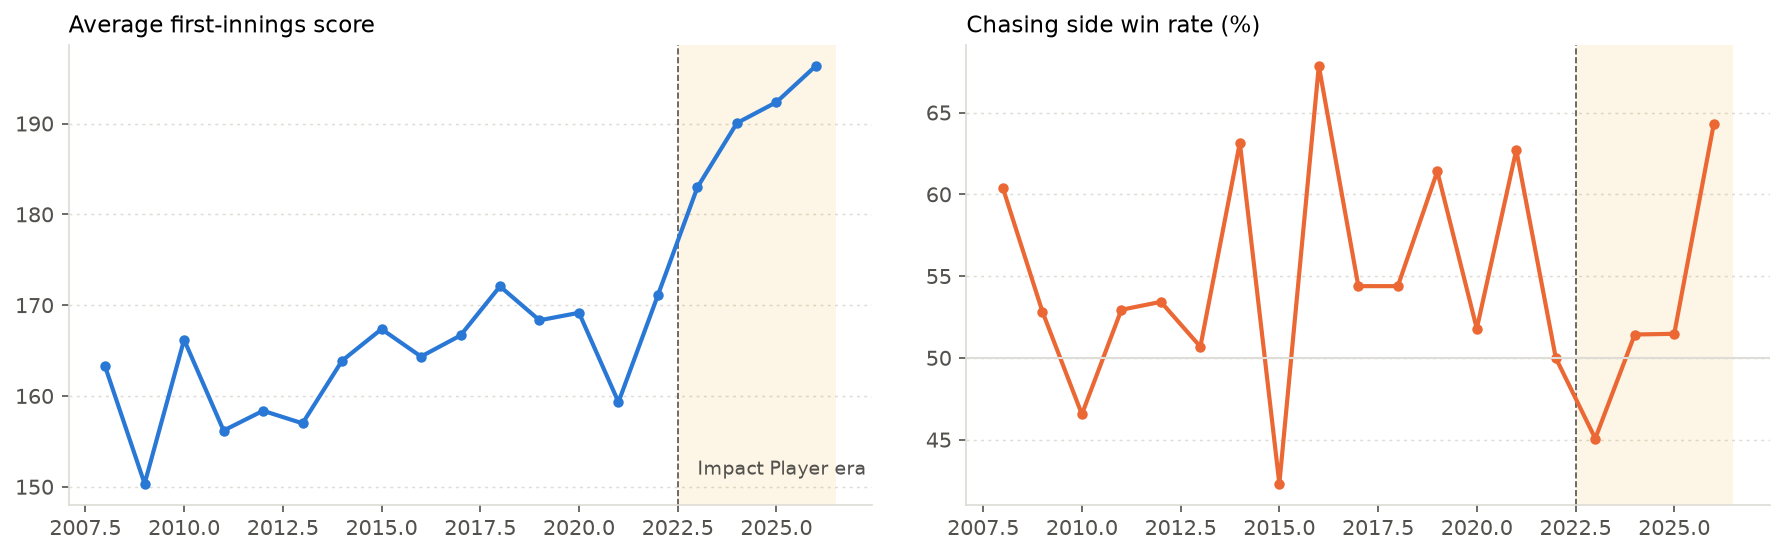

In [3]:
display(pd.read_csv(R / 'era_scoring_shift.csv', index_col=0).round(3))
F.fig_era(); plt.show()

## 2. Model selection (seasons <= 2024 only)
Rolling-origin backtests: each of 2021, 2022, 2023, 2024 is scored by a model trained only on strictly earlier seasons.

fold,2021,2022,2023,2024,all
model,,,,,
"GBM v0 (all features, 400 trees)",0.6887,0.6470,0.7484,0.8849,0.7428
"GBM v1 (regularised, state feats)",0.5334,0.5264,0.5903,0.4937,0.5363
logistic regression,0.5350,0.5223,0.5922,0.4953,0.5364
naive prior,0.6786,0.6985,0.7046,0.6948,0.6949
pre-match Elo only,0.6763,0.7084,0.7039,0.7040,0.6992


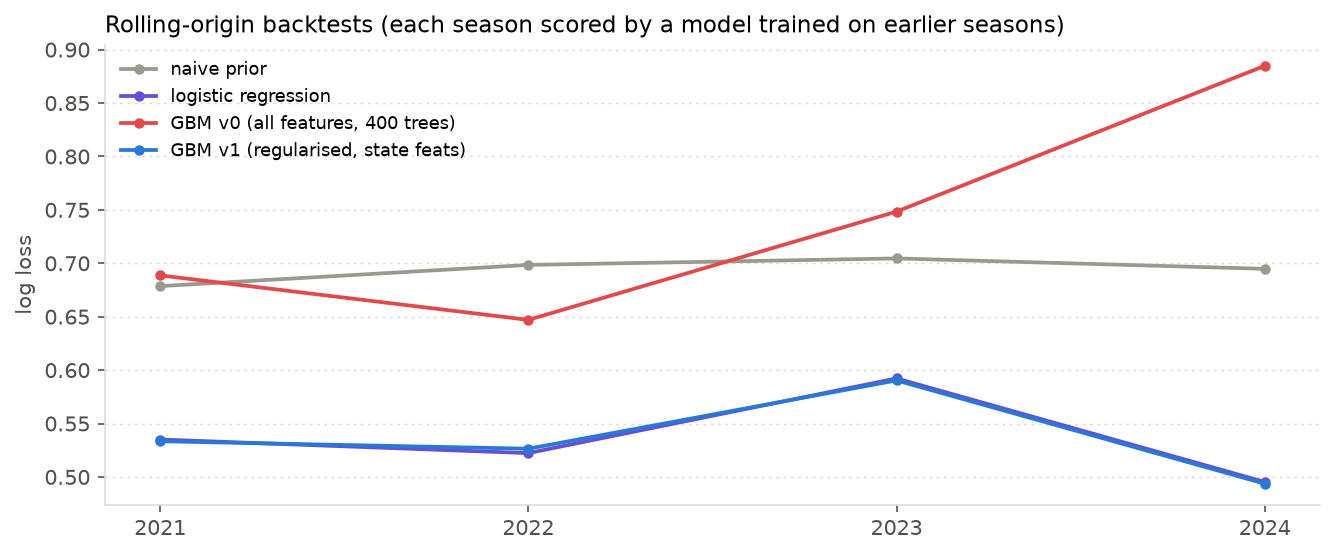

In [4]:
b = pd.read_csv(R / 'val_baselines.csv')
display(b.pivot(index='model', columns='fold', values='log_loss').round(4))
F.fig_backtest(); plt.show()

**Lesson 1: the first GBM was terrible (log loss 0.74, worse than coin-flipping on 2024).** It had match-constant features (venue, Elo, toss) and the chase target, so the trees memorised individual matches: every ball of a match shares those values, so a tree can carve out a single match and learn its outcome. The fix was to remove `target`/`runs` from the innings-2 features, use very shallow trees and large leaves, and to test every feature group with a pre-declared rule.

In [5]:
a = pd.read_csv(R / 'val_feature_ablation.csv'); display(a.round(4))

,group,innings,mean_delta,folds_better,n_folds,accept
0,form,1,-0.0006,2,4,False
1,form,2,-0.0003,2,4,False
2,relative_to_league,1,-0.0003,2,4,False
3,relative_to_league,2,-0.0008,3,4,False
4,venue,1,-0.0027,3,4,True
5,venue,2,-0.0026,3,4,True
6,league_avg_l40,1,0.0059,2,4,False
7,league_avg_l40,2,0.0024,3,4,False
8,toss,1,0.0002,1,4,False
9,toss,2,0.0009,1,4,False


Rule: a feature group is kept only if it lowers log loss by at least 0.001 on average **and** in at least 3 of the 4 backtest folds.

In [6]:
display(pd.read_csv(R / 'val_structure.csv', index_col=0).round(4))

,inn1,inn2,overall,fold_2021,fold_2022,fold_2023,fold_2024
joint (innings flag),0.6293,0.4534,0.5442,0.5350,0.5412,0.5986,0.4991
separate (state+venue),0.6218,0.4399,0.5338,0.5287,0.5244,0.5888,0.4914
separate + monotone,0.6224,0.4396,0.5340,0.5281,0.5230,0.5895,0.4935
"separate, 5 match-bagged",0.6223,0.4386,0.5334,0.5265,0.5231,0.5913,0.4906
"separate, boost from LR",0.6216,0.4317,0.5297,0.5274,0.5189,0.5851,0.4861
"separate, boost from LR + monotone",0.6223,0.4334,0.5309,0.5262,0.5172,0.5895,0.4892


In [7]:
display(pd.read_csv(R / 'val_era.csv', index_col=0).round(4))

,inn1,inn2,overall,fold_2021,fold_2022,fold_2023,fold_2024
+ impact_era flag,0.6234,0.4419,0.5356,0.5287,0.5244,0.5888,0.4985
"baseline (all history, uniform)",0.6218,0.4399,0.5338,0.5287,0.5244,0.5888,0.4914
recency half-life 1 season,0.6416,0.4577,0.5526,0.5353,0.5366,0.6304,0.5042
recency half-life 2 seasons,0.6317,0.4503,0.5439,0.5305,0.5350,0.6079,0.4988
recency half-life 4 seasons,0.6260,0.4453,0.5386,0.5280,0.5288,0.5975,0.4972
train only from 2016,0.6338,0.4533,0.5465,0.5320,0.5536,0.5967,0.4993
train only from 2018,0.6396,0.4541,0.5499,0.5430,0.5580,0.5966,0.4989


Recency weighting, restricting to recent seasons and an `impact_era` flag all made the backtests **worse**: more history beat more relevant history. (The state-based features already express a ball in terms of target and balls left, which transfers across eras.)

In [8]:
h = pd.read_csv(R / 'val_hparams.csv').sort_values('combined_ll'); display(h.head(6).round(4))
print(json.dumps(json.load(open(R / 'best_hparams.json')), indent=1))

,trial,num_leaves,min_child_samples,lambda_l2,feature_fraction,extra_trees,learning_rate,inn1_best_iter,inn1_best_ll,inn2_best_iter,inn2_best_ll,combined_ll
1,1,3,300,200.0,0.8,False,0.03,358,0.6177,477,0.4309,0.5273
8,8,3,600,10.0,0.8,False,0.03,281,0.6168,306,0.4333,0.5280
2,2,8,300,10.0,0.6,True,0.05,211,0.6204,147,0.4313,0.5289
9,9,12,600,200.0,0.8,False,0.02,100,0.6177,97,0.4347,0.5291
13,13,12,2000,1.0,0.6,False,0.05,32,0.6189,31,0.4337,0.5293
0,0,4,1000,NaN,NaN,True,0.03,675,0.6212,572,0.4314,0.5293


{
 "params": {
  "num_leaves": 3,
  "min_child_samples": 300,
  "lambda_l2": 200.0,
  "feature_fraction": 0.8,
  "extra_trees": false,
  "learning_rate": 0.03
 },
 "n_iter": {
  "1": 358,
  "2": 477
 },
 "trial": 1,
 "backtest_ll": {
  "1": 0.6176993558946995,
  "2": 0.4308619547233341
 }
}


In [9]:
display(pd.read_csv(R / 'val_monotone.csv', index_col=0).round(5))

,log_loss,brier,ece,roughness,viol_extra_wicket,viol_more_runs_inn2
model,,,,,,
GBM (monotone),0.52790,0.17877,0.04069,0.01526,0.0,0.00000
GBM (no constraints),0.52713,0.17849,0.04245,0.01519,0.0,0.00066
LR baseline,0.53620,0.18209,0.04459,0.01425,0.0,0.00000


Monotone constraints did not change anything measurable: because the booster starts from the logistic regression (which is monotone by construction), the unconstrained GBM already never gave a higher win probability for an extra wicket and almost never for fewer runs.

In [10]:
c = pd.read_csv(R / 'val_calibration.csv')
display(c.pivot(index='variant', columns='fold', values='log_loss').round(4))
display(c.pivot(index='variant', columns='fold', values='ece').round(4))

fold,2022,2023,2024,all
variant,,,,
isotonic,0.5273,0.7060,0.5216,0.5850
platt,0.5240,0.6277,0.5076,0.5532
raw,0.5157,0.5859,0.4896,0.5307


fold,2022,2023,2024,all
variant,,,,
isotonic,0.0463,0.1033,0.0624,0.0300
platt,0.0556,0.0996,0.0731,0.0251
raw,0.0507,0.0567,0.0347,0.0177


Nested backtest of post-hoc calibration (model trained before season y-1, calibrator fitted on y-1, scored on y): **it did not help** in any fold. That was the evidence available before the test, so the pre-declared headline model was the *uncalibrated* GBM; both calibrated variants are still reported below.

## 3. The test: train <= 2023, calibrate on 2024, score 2025-26

In [11]:
o = pd.read_csv(R / 'test_metrics_overall.csv', index_col=0)
order = ['naive prior','pre-match Elo only','logistic regression','logistic regression + Platt','logistic regression + isotonic','GBM','GBM + Platt','GBM + isotonic','GBM (monotone)','GBM (monotone) + Platt','GBM (monotone) + isotonic']
display(o.loc[order].round(4))

,n,log_loss,brier,auc,ece
model,,,,,
naive prior,31611,0.6863,0.2466,0.5693,0.0388
pre-match Elo only,31611,0.6874,0.2471,0.5723,0.0526
logistic regression,31611,0.5405,0.1850,0.7974,0.0433
logistic regression + Platt,31611,0.5193,0.1753,0.8203,0.0459
logistic regression + isotonic,31611,0.5350,0.1775,0.8155,0.0509
GBM,31611,0.5463,0.1867,0.7979,0.0557
GBM + Platt,31611,0.5303,0.1794,0.8147,0.0569
GBM + isotonic,31611,0.5595,0.1851,0.8023,0.0705
GBM (monotone),31611,0.5485,0.1874,0.7981,0.0627


In [12]:
ci = pd.read_csv(R / 'test_bootstrap_ci.csv').set_index('model')
t = pd.DataFrame({'log_loss 95% CI': ci.apply(lambda r: f"[{r.log_loss_lo:.3f}, {r.log_loss_hi:.3f}]", axis=1),
                  'log_loss diff vs LR 95% CI': ci.apply(lambda r: f"[{r.log_loss_vs_LR_lo:+.3f}, {r.log_loss_vs_LR_hi:+.3f}]", axis=1),
                  'brier diff vs LR 95% CI': ci.apply(lambda r: f"[{r.brier_vs_LR_lo:+.4f}, {r.brier_vs_LR_hi:+.4f}]", axis=1),
                  'ECE 95% CI': ci.apply(lambda r: f"[{r.ece_lo:.3f}, {r.ece_hi:.3f}]", axis=1)})
display(t)

,log_loss 95% CI,log_loss diff vs LR 95% CI,brier diff vs LR 95% CI,ECE 95% CI
model,,,,
naive prior,"[0.676, 0.696]","[+0.082, +0.201]","[+0.0350, +0.0847]","[0.003, 0.120]"
logistic regression,"[0.491, 0.598]","[+0.000, +0.000]","[+0.0000, +0.0000]","[0.029, 0.080]"
logistic regression + Platt,"[0.468, 0.578]","[-0.036, -0.006]","[-0.0155, -0.0035]","[0.033, 0.074]"
GBM,"[0.489, 0.609]","[-0.006, +0.018]","[-0.0027, +0.0061]","[0.039, 0.091]"
GBM (monotone),"[0.491, 0.611]","[-0.005, +0.021]","[-0.0022, +0.0071]","[0.043, 0.096]"
GBM + Platt,"[0.472, 0.597]","[-0.030, +0.011]","[-0.0128, +0.0014]","[0.038, 0.090]"
GBM + isotonic,"[0.483, 0.651]","[-0.025, +0.079]","[-0.0073, +0.0083]","[0.048, 0.112]"


Intervals come from resampling whole **matches** (500 draws), because balls within a match are not independent. 138 test matches is not many, so the intervals are wide: the honest reading is that GBM vs logistic regression is a tie, while both are clearly better than the naive prior.

In [13]:
s = pd.read_csv(R / 'test_metrics_by_season.csv')
display(s.pivot(index='model', columns='season', values='log_loss').loc[order].round(4))

season,2025,2026
model,,
naive prior,0.6948,0.6781
pre-match Elo only,0.7016,0.6735
logistic regression,0.5237,0.5568
logistic regression + Platt,0.5165,0.5219
logistic regression + isotonic,0.5468,0.5237
GBM,0.5288,0.5633
GBM + Platt,0.5260,0.5346
GBM + isotonic,0.5629,0.5562
GBM (monotone),0.5327,0.5638


In [14]:
full = pd.read_csv(R / 'test_metrics_full.csv')
for m in ['naive prior', 'logistic regression', 'GBM', 'GBM + Platt']:
    display(Markdown(f'**{m}**')); display(full[full.model == m].drop(columns='model').set_index('group').round(4))

**naive prior**

,n,log_loss,brier,auc,ece
group,,,,,
overall,31611,0.6863,0.2466,0.5693,0.0388
innings 1,16422,0.6840,0.2454,0.5000,0.0385
innings 2,15189,0.6888,0.2478,0.5000,0.0391
powerplay,9936,0.6854,0.2461,0.5797,0.0492
middle,14746,0.6857,0.2463,0.5758,0.0452
death,6929,0.6887,0.2478,0.5359,0.0280
inn1 powerplay,4968,0.6837,0.2453,0.5000,0.0403
inn1 middle,7447,0.6837,0.2453,0.5000,0.0401
inn1 death,4007,0.6848,0.2458,0.5000,0.0331


**logistic regression**

,n,log_loss,brier,auc,ece
group,,,,,
overall,31611,0.5405,0.1850,0.7974,0.0433
innings 1,16422,0.6731,0.2370,0.7075,0.1546
innings 2,15189,0.3972,0.1286,0.9150,0.0894
powerplay,9936,0.6149,0.2139,0.7217,0.0446
middle,14746,0.5181,0.1761,0.8217,0.0626
death,6929,0.4815,0.1623,0.8734,0.1116
inn1 powerplay,4968,0.6736,0.2402,0.6333,0.0921
inn1 middle,7447,0.6740,0.2381,0.7135,0.1651
inn1 death,4007,0.6706,0.2312,0.7891,0.2125


**GBM**

,n,log_loss,brier,auc,ece
group,,,,,
overall,31611,0.5463,0.1867,0.7979,0.0557
innings 1,16422,0.6895,0.2424,0.7035,0.1656
innings 2,15189,0.3915,0.1265,0.9109,0.0671
powerplay,9936,0.6082,0.2108,0.7280,0.0318
middle,14746,0.5319,0.1809,0.8151,0.0690
death,6929,0.4881,0.1645,0.8749,0.1222
inn1 powerplay,4968,0.6845,0.2447,0.6284,0.1076
inn1 middle,7447,0.6946,0.2448,0.7066,0.1780
inn1 death,4007,0.6863,0.2351,0.7854,0.2181


**GBM + Platt**

,n,log_loss,brier,auc,ece
group,,,,,
overall,31611,0.5303,0.1794,0.8147,0.0569
innings 1,16422,0.6727,0.2341,0.7035,0.1317
innings 2,15189,0.3765,0.1203,0.9109,0.0333
powerplay,9936,0.5857,0.2005,0.7567,0.0331
middle,14746,0.5185,0.1749,0.8292,0.0716
death,6929,0.4762,0.1588,0.8824,0.1177
inn1 powerplay,4968,0.6712,0.2384,0.6284,0.0709
inn1 middle,7447,0.6771,0.2363,0.7066,0.1468
inn1 death,4007,0.6664,0.2248,0.7854,0.1935


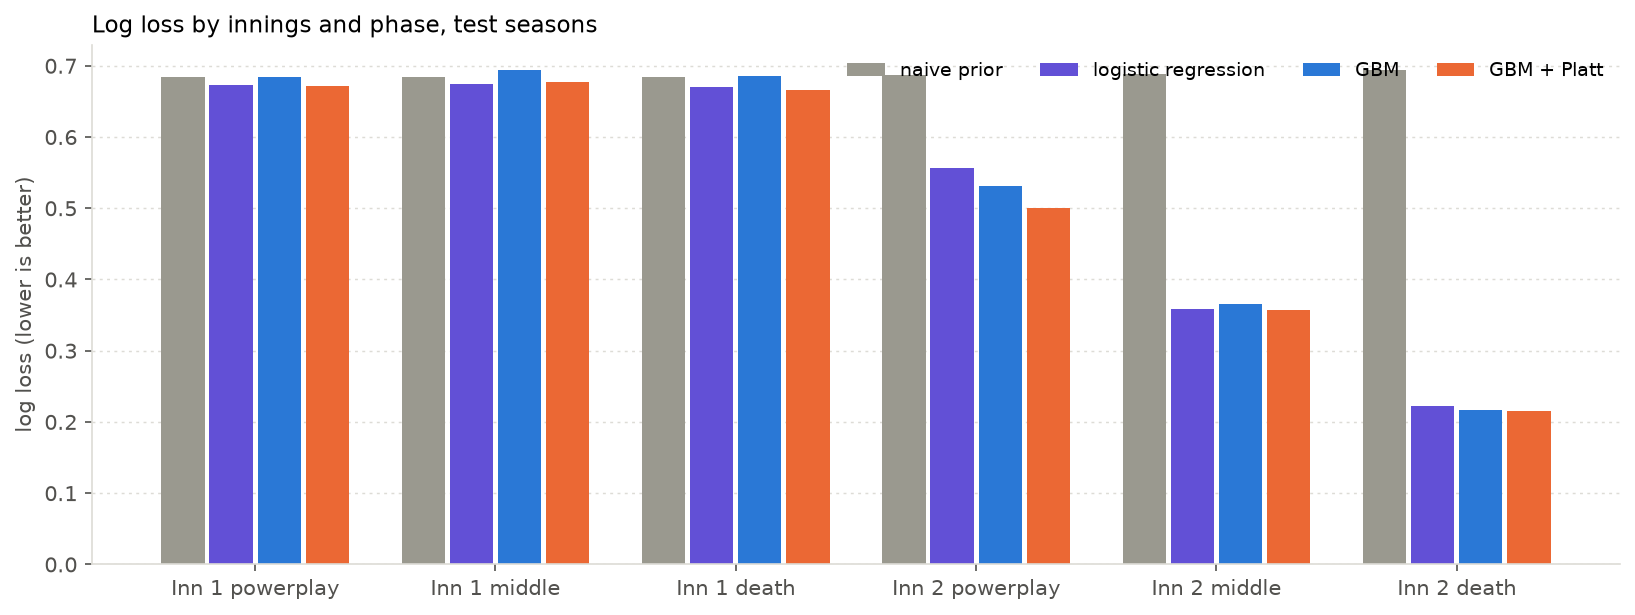

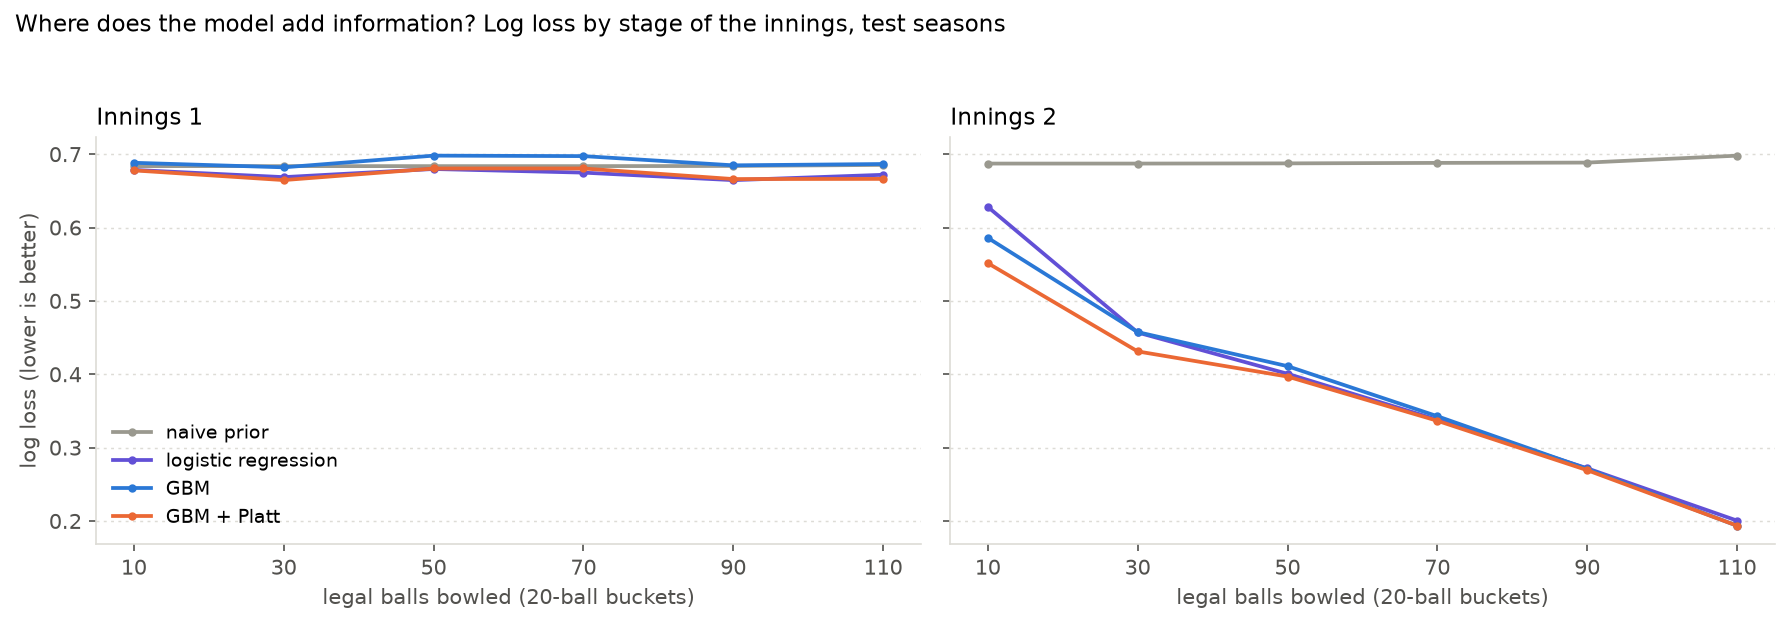

In [15]:
F.fig_phase(); plt.show(); F.fig_by_ball(); plt.show()

## 4. Calibration, before and after

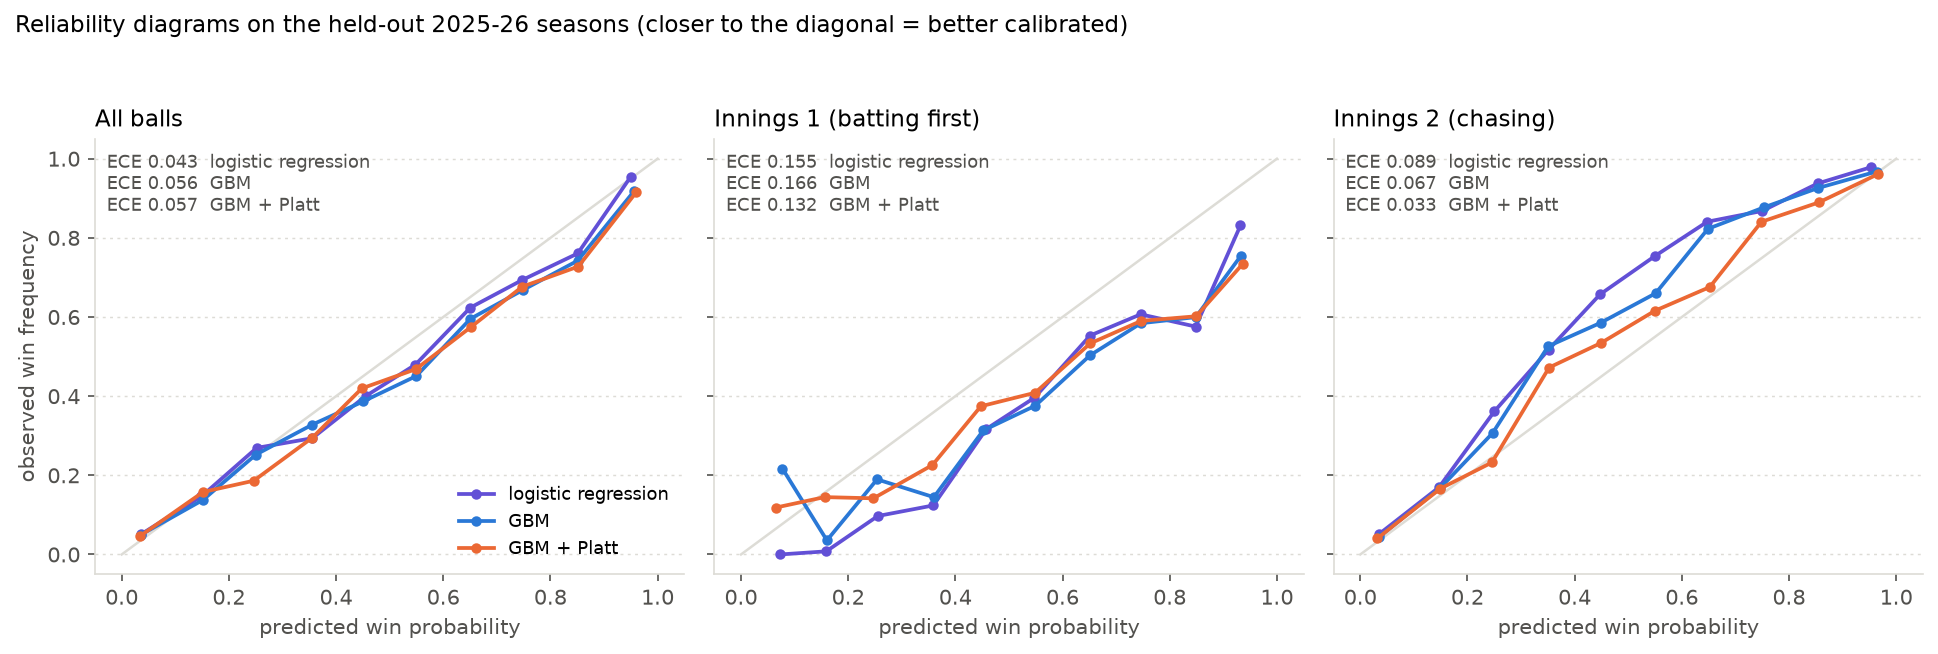

actual     LR    GBM  GBM_Platt
season innings                                 
2025   1         0.488  0.571  0.578      0.542
       2         0.487  0.456  0.479      0.517
2026   1         0.359  0.583  0.594      0.562
       2         0.633  0.487  0.508      0.546

In [16]:
F.fig_reliability(); plt.show()
act = pd.read_parquet(R / 'test_predictions.parquet')
g = act.groupby(['season', 'innings']).agg(actual=('bat_team_wins', 'mean'), LR=('logistic regression', 'mean'), GBM=('GBM', 'mean'), GBM_Platt=('GBM + Platt', 'mean'))
display(g.round(3))

The raw models are **optimistic about the side that bats first** in both test seasons (mean predicted ~0.57 vs observed 0.49 in 2025, and 0.36 observed in 2026, a season where chasing teams won 63% of matches). Platt scaling fitted on 2024 removes part of this, which is why it improves log loss and Brier. It does not improve ECE in every slice: ECE on ~138 matches is noisy, so look at the confidence intervals above before reading anything into a 0.00x gap.

## 5. Turning points

In [17]:
sw = pd.read_csv(R / 'test_biggest_swings.csv'); sw['swing_pts'] = (sw.swing * 100).round(1)
display(sw[['season','date','match','innings','ball','event_text','p_before','p_after','swing_pts']].head(15).round(3))

,season,date,match,innings,ball,event_text,p_before,p_after,swing_pts
0,2026,2026-04-09,KKR v LSG,2,19.5,SIX: MD Choudhary off VG Arora,0.943,0.047,-89.7
1,2026,2026-04-08,GT v DC,2,19.4,SIX: DA Miller off M Prasidh Krishna,0.753,0.042,-71.1
2,2025,2025-05-03,RCB v CSK,2,19.5,"1 run(s), RA Jadeja off Yash Dayal",0.389,0.935,54.7
3,2025,2025-05-03,RCB v CSK,2,19.3,"WICKET: MS Dhoni lbw, b Yash Dayal",0.692,0.188,-50.5
4,2026,2026-05-10,MI v RCB,2,19.4,SIX: B Kumar off RA Bawa,0.961,0.462,-49.9
5,2026,2026-04-18,RCB v DC,2,19.3,SIX: DA Miller off R Shepherd,0.710,0.225,-48.6
6,2025,2025-04-19,LSG v RR,2,19.4,"Dot ball, Avesh Khan to SB Dubey",0.215,0.693,47.9
7,2026,2026-04-09,KKR v LSG,2,19.2,SIX: MD Choudhary off VG Arora,0.751,0.293,-45.7
8,2026,2026-05-14,PBKS v MI,2,19.4,SIX: Tilak Varma off XC Bartlett,0.423,0.011,-41.3
9,2025,2025-03-24,LSG v DC,2,18.5,SIX: Ashutosh Sharma off Prince Yadav,0.771,0.386,-38.5


In [18]:
display(pd.read_csv(R / 'swing_event_mix.csv', index_col=0).round(3))
display(pd.read_csv(R / 'swing_by_event_type.csv', index_col=0).round(4))
ov = pd.read_csv(R / 'test_biggest_overs.csv'); ov['swing_pts'] = (ov.swing * 100).round(1)
display(ov[['season','date','match','innings','over','bowler','runs','wkts','swing_pts']].head(10))
gap = pd.read_csv(R / 'handover_gap.csv'); print('innings-break hand-over gap (|P2_start - P1_end|), mean/median/max:', gap.handover_gap.mean().round(3), gap.handover_gap.median().round(3), gap.handover_gap.max().round(3))

,share_of_top200_swings,share_of_all_balls
event_type,,
wicket,0.570,0.052
six,0.285,0.084
four,0.060,0.134
runs,0.045,0.482
dot,0.040,0.248


,mean,median,size
event_type,,,
dot,0.0127,0.0090,6950
four,0.0285,0.0239,3748
runs,0.0042,0.0008,13502
six,0.0478,0.0383,2359
wicket,0.0597,0.0525,1464


,season,date,match,innings,over,bowler,runs,wkts,swing_pts
0,2025,2025-04-19,LSG v RR,2,20,Avesh Khan,6,1,94.3
1,2025,2025-04-15,PBKS v KKR,2,16,M Jansen,0,1,89.7
2,2026,2026-04-04,RR v GT,2,20,TU Deshpande,3,1,74.3
3,2026,2026-05-10,MI v RCB,2,20,RA Bawa,13,1,-73.4
4,2025,2025-04-24,RCB v RR,2,19,JR Hazlewood,1,2,72.9
5,2025,2025-05-03,RCB v CSK,2,20,Yash Dayal,12,1,66.6
6,2026,2026-04-09,KKR v LSG,2,20,VG Arora,14,0,-63.7
7,2026,2026-04-08,GT v DC,2,20,M Prasidh Krishna,11,2,58.2
8,2025,2025-04-04,LSG v MI,2,19,SN Thakur,7,1,55.3
9,2025,2025-03-24,LSG v DC,2,19,Prince Yadav,16,1,-49.7


innings-break hand-over gap (|P2_start - P1_end|), mean/median/max: 0.089 0.071 0.277


**comeback**

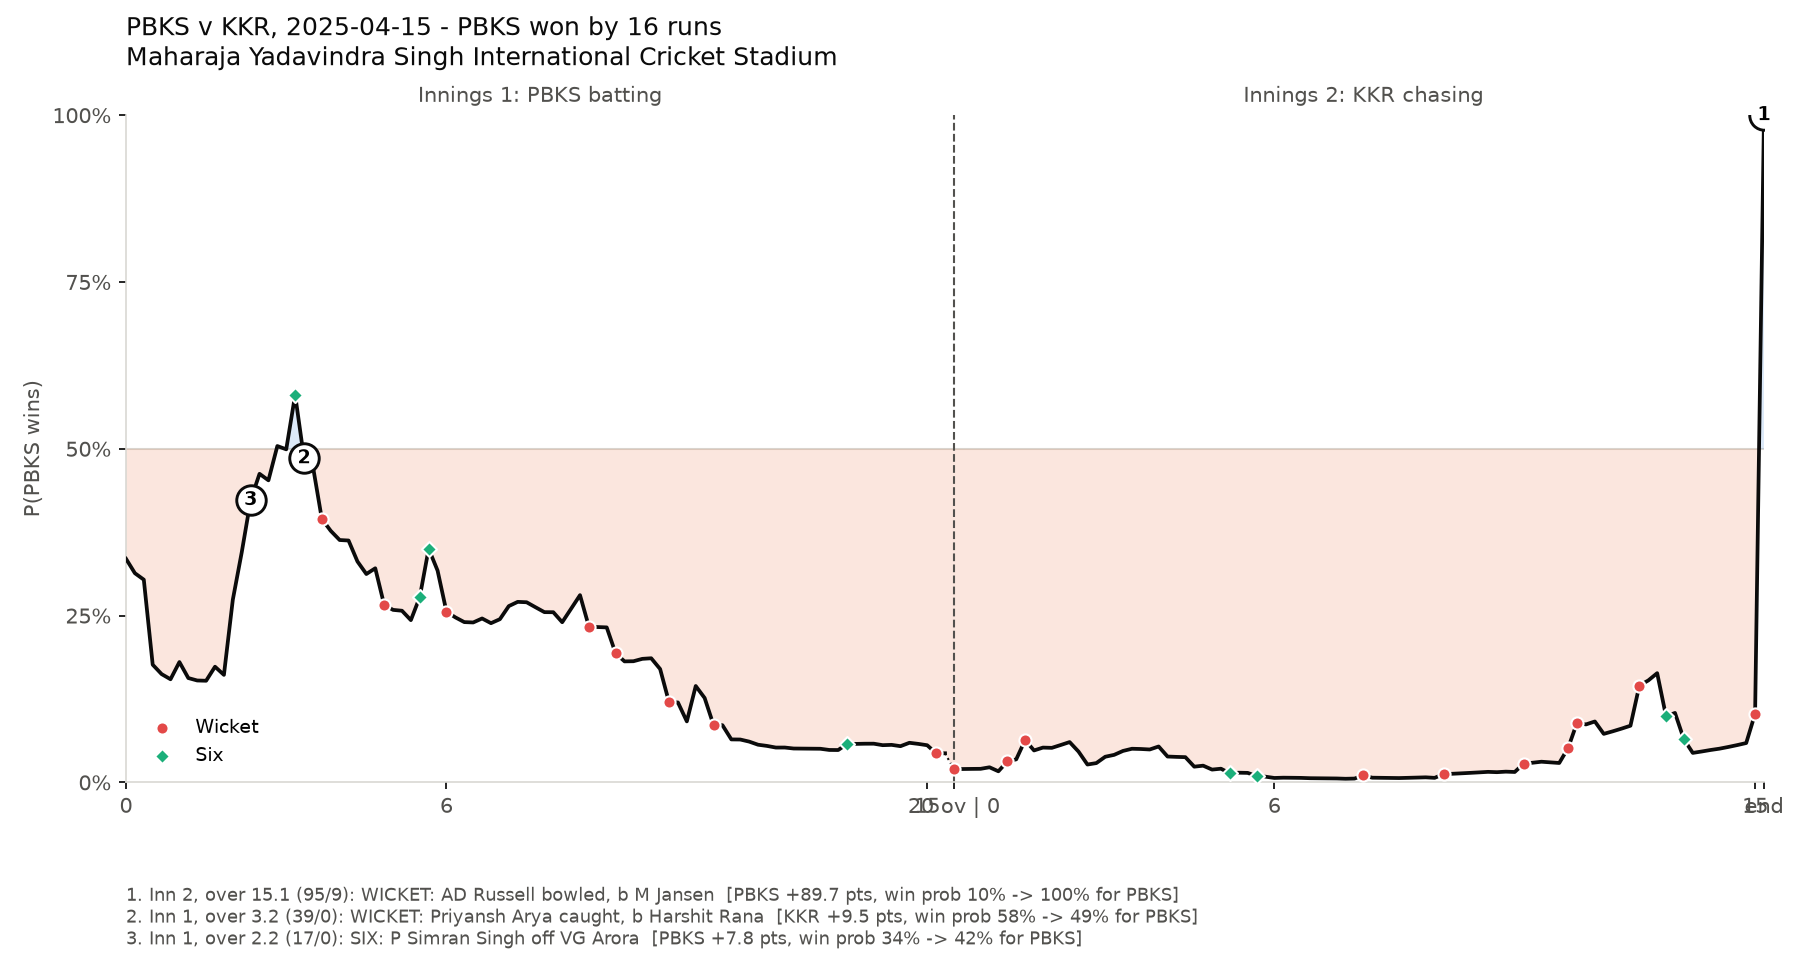

**biggest_swing**

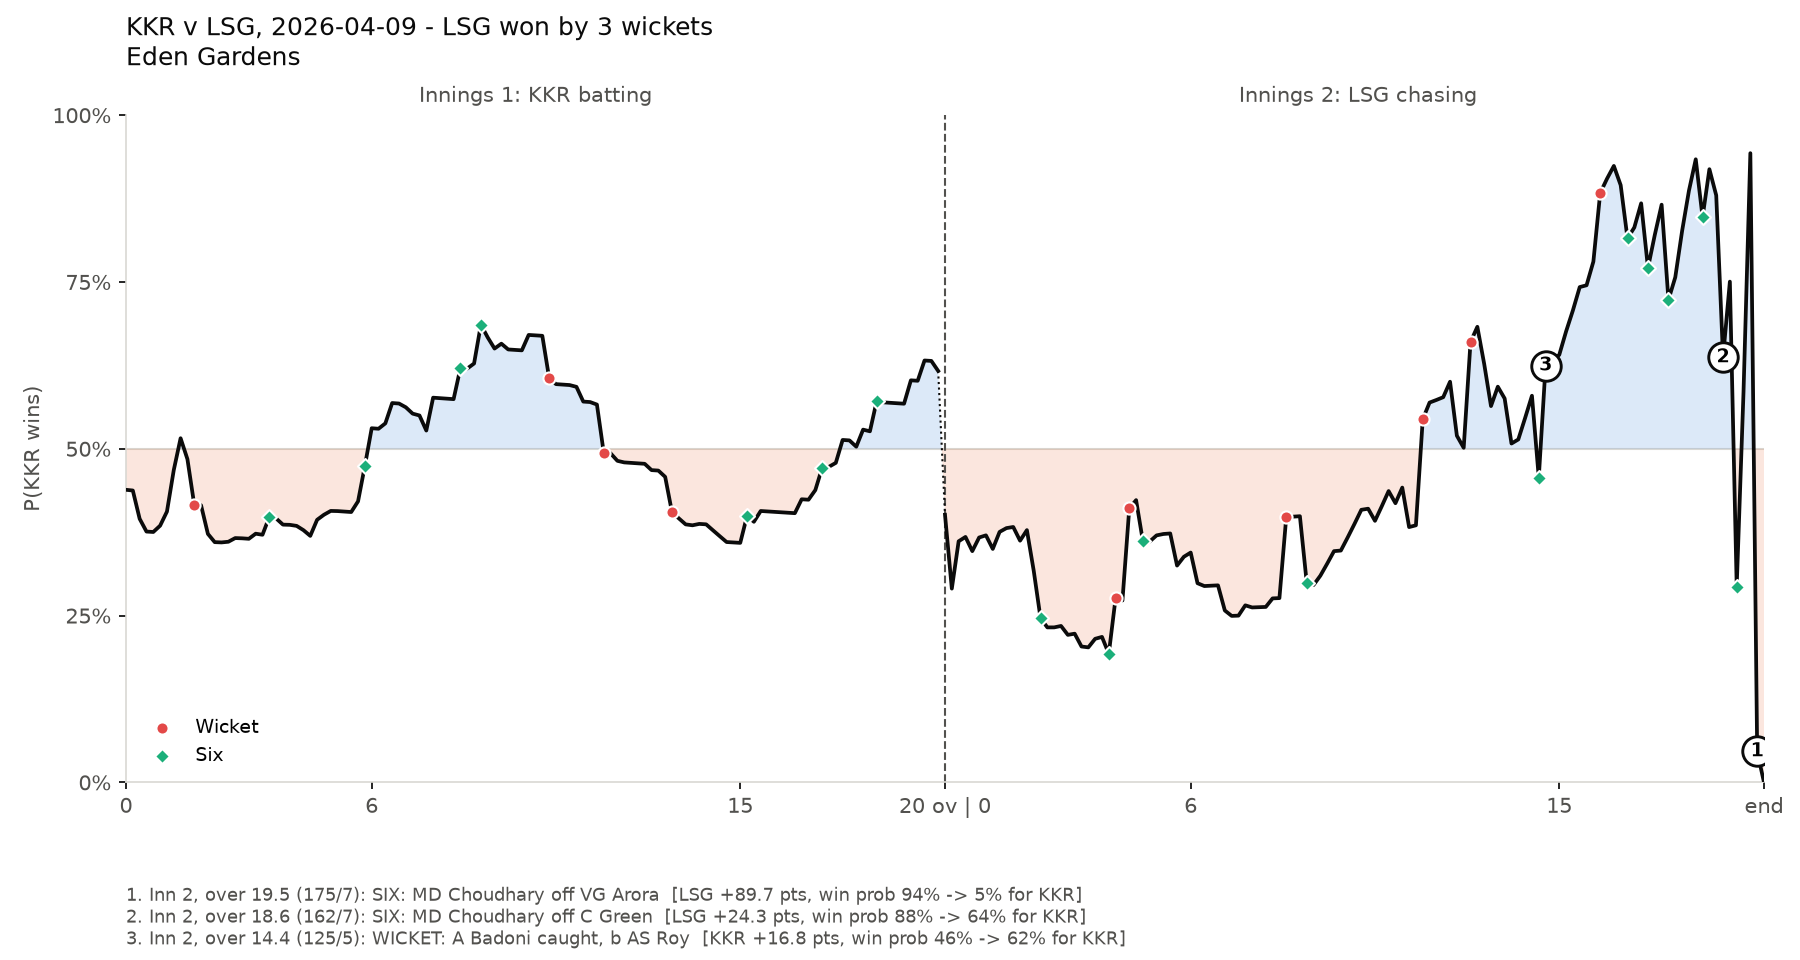

**seesaw**

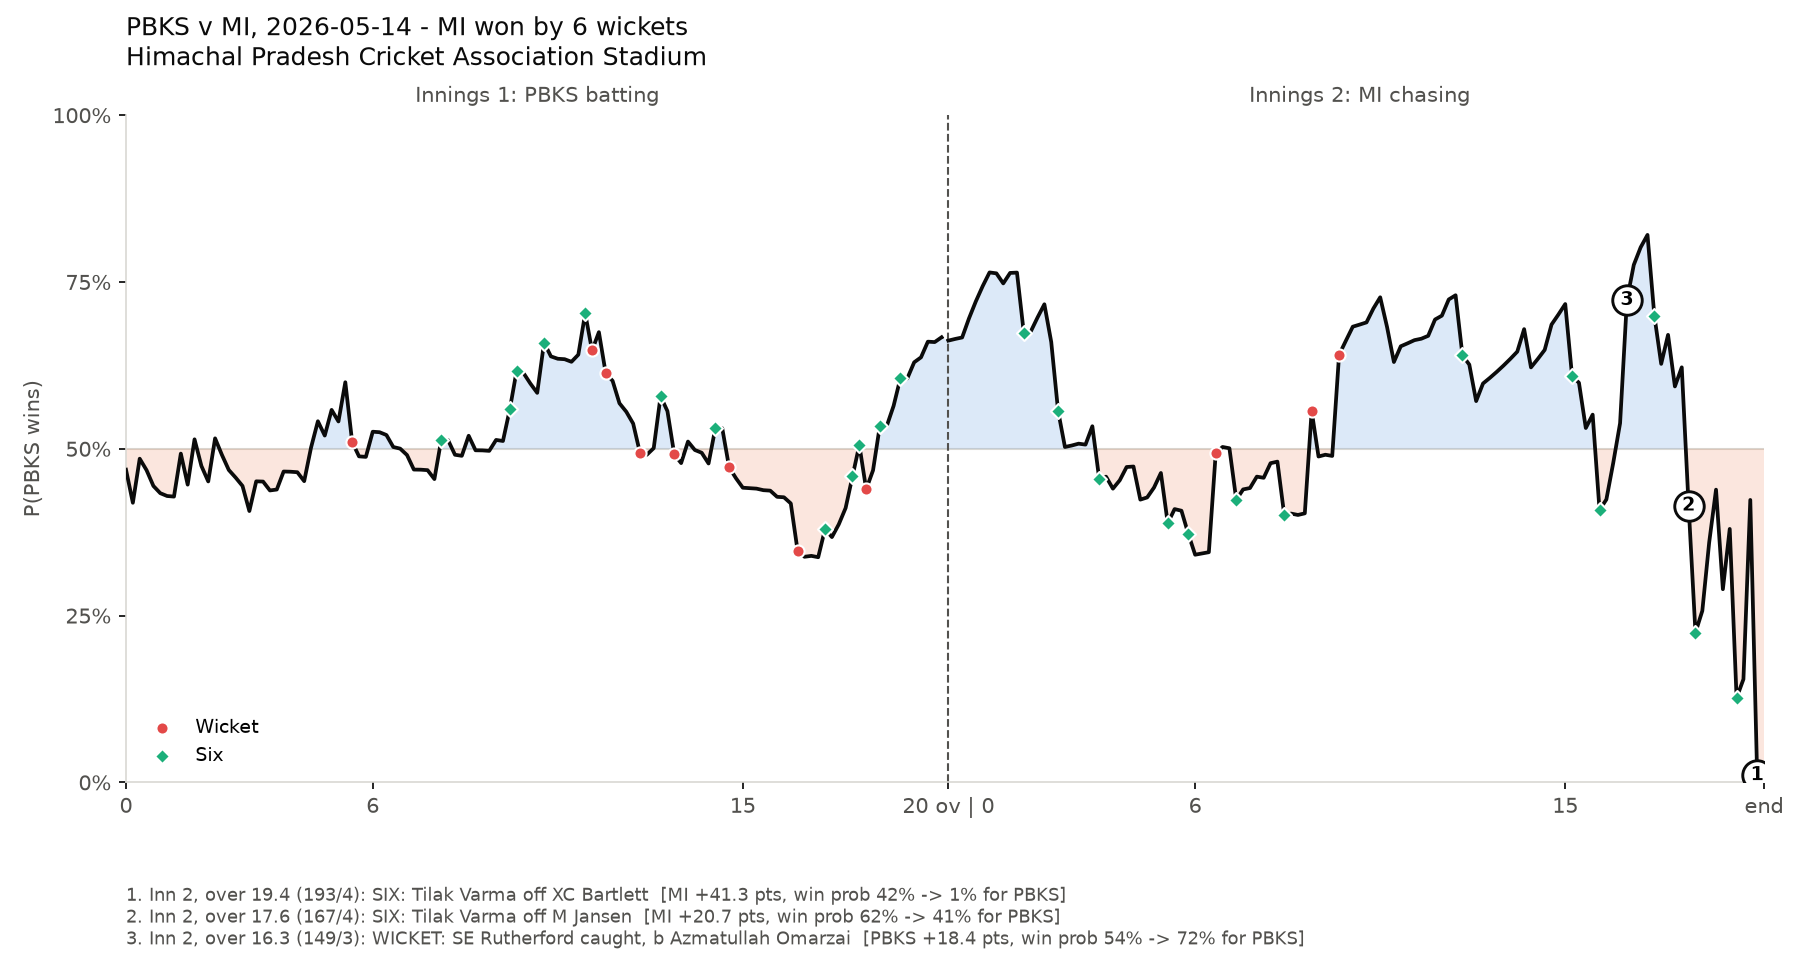

In [19]:
sel = json.load(open(R / 'replay_png_matches.json'))
for tag in sel:
    display(Markdown(f'**{tag}**')); display(Image(filename=str(FIG / f'replay_{tag}.png')))

## 6. Post-hoc follow-up (exploratory)
After seeing that the test-season failure mode was era drift, I tried features expressed relative to the recent league scoring level. Because the idea came from looking at the test seasons, **these numbers are not an unbiased estimate**; they are a lead for future work.

In [20]:
display(pd.read_csv(R / 'posthoc_era_metrics.csv').round(4))
display(pd.read_csv(R / 'posthoc_era_by_innings.csv').pivot(index='model', columns='group', values='log_loss').round(4))
display(pd.read_csv(R / 'posthoc_era_backtest_lr.csv').pivot(index='model', columns='fold', values='log_loss').round(4))

,model,n,log_loss,brier,auc,ece
0,logistic regression [frozen run],31611,0.5405,0.1850,0.7974,0.0433
1,GBM [frozen run],31611,0.5463,0.1867,0.7979,0.0557
2,GBM + Platt [frozen run],31611,0.5303,0.1794,0.8147,0.0569
3,logistic regression + Platt [frozen run],31611,0.5193,0.1753,0.8203,0.0459
4,LR (relative feats),31611,0.5241,0.1779,0.8263,0.0808
5,LR (relative feats) + Platt,31611,0.5137,0.1733,0.8250,0.0489
6,"GBM (relative feats, boost from rel-LR)",31611,0.5323,0.1812,0.8184,0.0810
7,"GBM (relative feats, boost from rel-LR) + Platt",31611,0.5219,0.1767,0.8190,0.0532


group,innings 1,innings 2,overall
model,,,
"GBM (relative feats, boost from rel-LR)",0.6823,0.3701,0.5323
"GBM (relative feats, boost from rel-LR) + Platt",0.6672,0.3648,0.5219
LR (relative feats),0.6690,0.3675,0.5241
LR (relative feats) + Platt,0.6567,0.3592,0.5137


fold,2021,2022,2023,2024,all
model,,,,,
LR,0.5350,0.5223,0.5922,0.4953,0.5364
LR relative feats,0.5352,0.5299,0.5898,0.4932,0.5374
